# 06 · Manager scorecard, business interpretation and deployment
## Summary
Organize the decision around three questions: improvement over RTE; uncertainty and failures; deployment and risks. Forecast skill is measured on matched observations under explicit retrospective assumptions. Procurement savings cannot be estimated from demand, temperatures and RTE alone.
## Context and methods
Use the frozen candidate and saved test forecasts. No model or feature is changed here. National consumption is a utility-demand proxy. The holdout was previously explored, weather/RTE vintages are unverified and the hourly conversion is undocumented: these constrain the recommendation even if retrospective loss improves.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/forecast_contract.json").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.common import load_contract, prepare_directories, plotting_style, write_json, fingerprint
contract = load_contract(ROOT)
prepare_directories(ROOT)
plotting_style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 16)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
from src.storage import read_predictions,read_labels
from src.data import read_audited,availability_gate
from src.pipeline import readiness,monitoring_specification,risk_register
from src.metrics import point_metrics
frozen=json.loads((ROOT/"config/frozen_candidate.json").read_text()); name=frozen["experiment"]["name"]
scores=pd.read_csv(ROOT/"reports/scorecards/test_common.csv")
ci=pd.read_csv(ROOT/"reports/scorecards/paired_block_bootstrap.csv")
predictions=read_predictions(ROOT/"reports/forecasts/all_test.csv.gz")
labels=read_labels(ROOT/"data/processed/evaluation_labels.csv.gz")

### 1. Does it improve on the provided RTE benchmark?

,model,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent
0,seasonal_naive,"8,759.000","8,759.000",1.000,1.000,"3,424.948","5,060.040",52.071,6.760
1,comparable_days,"8,759.000","8,759.000",1.000,1.000,"3,818.657","5,374.144",94.938,7.537
2,rte_proxy,"8,759.000","8,759.000",1.000,1.000,"1,438.982","1,782.647","1,085.830",2.840
3,rte_bias_proxy,"8,759.000","8,759.000",1.000,1.000,"1,111.048","1,412.837",3.636,2.193
4,rte_correction_proxy,"8,759.000","8,759.000",1.000,1.000,832.047,"1,090.315",134.827,1.642


,block_days,status,paired_days,partially_observed_days_retained,paired_hours,relative_improvement_percent,relative_low,relative_high,absolute_MAE_improvement_MW,absolute_low,absolute_high
0,7,ok,365,1,8759,42.178,38.173,46.407,606.935,534.154,687.818
1,14,ok,365,1,8759,42.178,37.360,47.533,606.935,535.431,703.937
2,28,ok,365,1,8759,42.178,35.625,48.672,606.935,511.049,731.956


**Frozen candidate:** `rte_correction_proxy`. Matched test MAE improvement over provided RTE: **42.18%**, or **606.9 MW**. This is retrospective skill, not operational validation or financial savings.

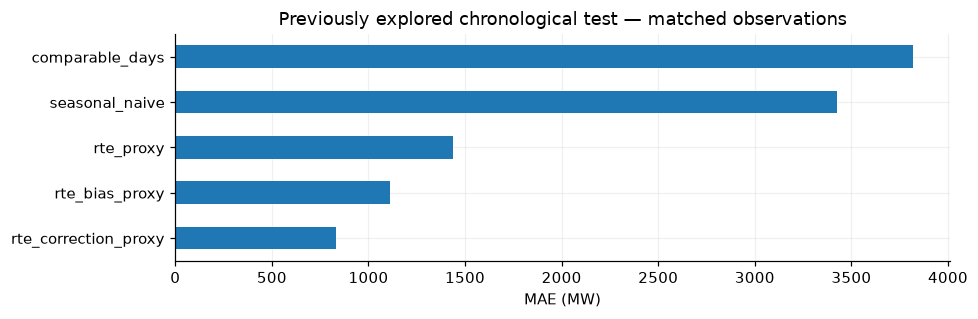

In [3]:
display(scores); display(ci)
reference=scores.set_index("model").loc["rte_proxy"]
candidate_score=scores.set_index("model").loc[name]
relative=100*(1-candidate_score.MAE_MW/reference.MAE_MW)
absolute=reference.MAE_MW-candidate_score.MAE_MW
display(Markdown(f"**Frozen candidate:** `{name}`. Matched test MAE improvement over provided RTE: **{relative:.2f}%**, or **{absolute:,.1f} MW**. This is retrospective skill, not operational validation or financial savings."))
fig,ax=plt.subplots(figsize=(9,3))
scores.set_index("model").MAE_MW.sort_values().plot.barh(ax=ax)
ax.set(title="Previously explored chronological test — matched observations",xlabel="MAE (MW)",ylabel="")
plt.tight_layout(); plt.show()

### 2. How uncertain are forecasts, and where do they fail?

In [4]:
calibration=pd.read_csv(ROOT/"reports/uncertainty/quantile_calibration.csv")
display(calibration.loc[calibration.segment_type.isin(["overall","cold_evening"])])
display(pd.read_csv(ROOT/"reports/failure_catalogue.csv").head(5))
daily=pd.read_csv(ROOT/"reports/scorecards/test_daily.csv")
display(daily.groupby("model")[["absolute_daily_energy_error_MWh","absolute_daily_peak_error_MW","shortage_proxy_MWh","surplus_proxy_MWh"]].mean())

,segment_type,segment,eligible_targets,scored,interval_availability,coverage_90,width_MW,lower_exceedance,upper_exceedance,pinball_0.05,pinball_0.50,pinball_0.95
0,overall,all,8759,8759,1.000,0.811,"2,811.492",0.080,0.110,108.780,416.024,127.458
29,cold_evening,False,8693,8693,1.000,0.812,"2,798.762",0.080,0.108,108.237,411.718,125.147
30,cold_evening,True,66,66,1.000,0.667,"4,488.113",0.000,0.333,180.320,983.149,431.882


,day,MAE_MW,max_error_MW,fallback_intervals,minimum_temperature_C,source_reconciliation_flags,scored_intervals,classification,weather_miss_verified
0,2025-12-01,"2,688.154","4,067.601",0,2.700,0,24,unexplained,False
1,2026-01-05,"2,685.565","5,619.096",0,-3.540,0,24,unexplained,False
2,2025-12-26,"2,432.148","5,535.420",0,-0.330,0,24,unexplained,False
3,2026-05-01,"2,339.428","3,567.615",0,12.030,0,24,unexplained,False
4,2025-10-27,"2,337.765","3,987.188",0,9.500,0,24,unexplained,False


,absolute_daily_energy_error_MWh,absolute_daily_peak_error_MW,shortage_proxy_MWh,surplus_proxy_MWh
model,,,,
comparable_days,"89,098.136","3,850.000","46,817.441","44,802.272"
rte_bias_proxy,"14,663.802",998.322,"13,395.865","13,297.927"
rte_correction_proxy,"14,578.204",957.110,"11,617.735","8,377.796"
rte_proxy,"27,757.440","1,723.104","30,323.209","4,245.335"
seasonal_naive,"79,077.852","3,507.772","41,659.143","40,581.093"


### 3. Can it be deployed, and what are the business limits?
Demand forecasting and procurement decisions are separate. Euro savings require actual prices, settlement rules for the evaluation dates, market instruments, and an explicit shortage/surplus procurement policy applied identically to RTE and the candidate. Realized future prices may evaluate that policy retrospectively but cannot be auction-time input features.

EU day-ahead markets introduced **15-minute market time units for delivery from 1 October 2025**. The assignment retains hourly targets; quarter-hour forecasting and settlement alignment remain additional production work. [European Commission](https://energy.ec.europa.eu/news/eu-electricity-trading-day-ahead-markets-becomes-more-dynamic-2025-10-01_en)

In [5]:
data=read_audited(ROOT)
# Client date is explicit; never assume that a June data extract is fresh in October.
assessment_origin=pd.Timestamp("2026-10-20 11:00",tz=contract["timezone"]).tz_convert("UTC")
readiness_report=readiness(ROOT,data,assessment_origin,contract)
display(pd.Series(readiness_report).to_frame("deployment_readiness"))
monitoring=monitoring_specification(); risks=risk_register()
monitoring.to_csv(ROOT/"reports/monitoring_specification.csv",index=False)
risks.to_csv(ROOT/"reports/risk_register.csv",index=False)
display(monitoring); display(risks)

,deployment_readiness
origin,2026-10-20 09:00:00+00:00
latest_known_demand_age_hours,"2,676.000"
demand_fresh_under_assumed_delay,False
verified_operational_gate_passed,False
publish_procurement_decision,False
recommendation,retrospective research / shadow design only un...


,stage,check,response
0,ingestion,"file schema, checksums, duplicates, missing in...",fail run on ambiguous keys; retain last archiv...
1,freshness,"weather issue/availability, RTE publication, d...",reject stale runs; declared fallback or explic...
2,snapshot,origin/delivery keys; maximum input availability,reject any input after cutoff
3,forecast,finite positive predictions; complete delivery...,RTE if verified/available for assisted model; ...
4,uncertainty,"coverage, width, upper/lower exceedances, samp...",flag uncalibrated interval; do not fabricate a...
5,delivery,runtime and completion before agreed deadline,publish fallback before deadline or mark misse...
6,archive,"predictions, issue versions, model/config/sour...",write immutable run identifier before accessin...
7,monitor,"MAE, cold-evening MAE, fallback frequency and ...",shadow review; refit only under frozen online ...


,risk,consequence,mitigation
0,unknown vintages,revised data can leak into historical inputs,obtain original publication/issue archives; ke...
1,unknown hourly aggregation,target and benchmark may represent different i...,verify extraction recipe and interval labels b...
2,previously explored holdout,selection may be influenced by full-history EDA,fresh prospective shadow period
3,national proxy,utility customer mix may behave differently,portfolio-specific retraining and validation
4,weather miss,forecast weather differs from delivery conditions,authentic weather archive; stale/missing-input...
5,rare extremes,few cold or hot observations,segment counts and trajectory-aware stress eva...
6,settlement alignment,hourly target differs from 15-minute market units,quarter-hour forecasting and settlement integr...
7,financial inference,lower forecast loss need not mean lower costs,"prices, period-specific rules, instruments and..."


### 4. Save the manager-facing recommendation

In [6]:
overall=calibration.loc[calibration.segment_type.eq("overall")].iloc[0]
empirical_table=pd.read_csv(ROOT/"reports/uncertainty/empirical_calibration.csv")
empirical_overall=empirical_table.loc[empirical_table.segment_type.eq("overall")].iloc[0]
recommendation=f"""# Electricity demand forecasting — final research assessment

## 1. Improvement over RTE
Frozen candidate: {name}, an RTE-assisted additive correction, not an independent replacement. Matched test MAE: {candidate_score.MAE_MW:,.2f} MW; provided RTE: {reference.MAE_MW:,.2f} MW. Relative improvement: {relative:.2f}%; absolute MAE reduction: {absolute:,.2f} MW.
Read reports/scorecards/paired_block_bootstrap.csv for paired 7/14/28-day block sensitivity and confidence intervals. These retain exactly the same eligible paired hours as headline MAE, including partial days with their actual counts. Calendar-day blocks preserve dependence; hourly errors are not resampled independently.

## 2. Uncertainty and failures
Nominal 90% quantile interval coverage: {overall.coverage_90:.3f}; mean width: {overall.width_MW:,.1f} MW. The fixed rolling past-error baseline has coverage {empirical_overall.coverage_90:.3f}. Quantile coverage below 90% indicates undercoverage, not successful calibration; further method development must use validation or a new prospective period, not discretionary tuning on this test. Coverage, tail exceedances and pinball losses by hour, season, cold evenings and lead time are in reports/uncertainty/. Complete residual-day scenarios evaluate daily energy and peaks separately. Unsupported DST sample sizes remain explicit.
Worst-day evidence is in reports/failure_catalogue.csv. Weather misses cannot be verified without archived forecast weather. Do not infer causes from coincidence.

## 3. Deployment and risks
Recommendation: retrospective research and prospective shadow validation only; no procurement deployment claim. Forecast vintages, source-to-hourly conversion and original observation publication times are unverified. The chronological test was previously explored in EDA. Demand history uses a disclosed publication-delay/revision approximation.
The October readiness check also finds that the supplied extract ends in June: a live system must reject stale inputs. National consumption is not a validated customer portfolio model. Energy shortage/surplus proxies are not euro savings. Prices, applicable settlement rules and a common procurement policy are required for financial claims; quarter-hour production alignment is additional work.

Pipeline: ingest -> validate freshness -> cutoff snapshot -> point/uncertainty forecast -> declared fallback -> archive/publish on time -> monitor. Begin with shadow operation and monitor the complete policy, including fallback days. See monitoring_specification.csv and risk_register.csv.
"""
(ROOT/"reports/final_recommendation.md").write_text(recommendation)
write_json(ROOT/"reports/run_summary.json",{"candidate":name,"test_MAE_MW":candidate_score.MAE_MW,"rte_test_MAE_MW":reference.MAE_MW,"relative_improvement_percent":relative,"absolute_improvement_MW":absolute,"coverage_90":overall.coverage_90,"operationally_validated":False,"financial_savings_estimable":False,"test_previously_explored":True})
display(Markdown(recommendation))

# Electricity demand forecasting — final research assessment

## 1. Improvement over RTE
Frozen candidate: rte_correction_proxy, an RTE-assisted additive correction, not an independent replacement. Matched test MAE: 832.05 MW; provided RTE: 1,438.98 MW. Relative improvement: 42.18%; absolute MAE reduction: 606.94 MW.
Read reports/scorecards/paired_block_bootstrap.csv for paired 7/14/28-day block sensitivity and confidence intervals. These retain exactly the same eligible paired hours as headline MAE, including partial days with their actual counts. Calendar-day blocks preserve dependence; hourly errors are not resampled independently.

## 2. Uncertainty and failures
Nominal 90% quantile interval coverage: 0.811; mean width: 2,811.5 MW. The fixed rolling past-error baseline has coverage 0.890. Quantile coverage below 90% indicates undercoverage, not successful calibration; further method development must use validation or a new prospective period, not discretionary tuning on this test. Coverage, tail exceedances and pinball losses by hour, season, cold evenings and lead time are in reports/uncertainty/. Complete residual-day scenarios evaluate daily energy and peaks separately. Unsupported DST sample sizes remain explicit.
Worst-day evidence is in reports/failure_catalogue.csv. Weather misses cannot be verified without archived forecast weather. Do not infer causes from coincidence.

## 3. Deployment and risks
Recommendation: retrospective research and prospective shadow validation only; no procurement deployment claim. Forecast vintages, source-to-hourly conversion and original observation publication times are unverified. The chronological test was previously explored in EDA. Demand history uses a disclosed publication-delay/revision approximation.
The October readiness check also finds that the supplied extract ends in June: a live system must reject stale inputs. National consumption is not a validated customer portfolio model. Energy shortage/surplus proxies are not euro savings. Prices, applicable settlement rules and a common procurement policy are required for financial claims; quarter-hour production alignment is additional work.

Pipeline: ingest -> validate freshness -> cutoff snapshot -> point/uncertainty forecast -> declared fallback -> archive/publish on time -> monitor. Begin with shadow operation and monitor the complete policy, including fallback days. See monitoring_specification.csv and risk_register.csv.
